# Student Performance Data Explorer

## Objective
Explore the genuine UCI Student Performance mathematics data, assess data quality, describe final grades, and communicate patterns with plots. Correlation is descriptive and does not establish causation.

**Source:** [UCI Student Performance (dataset 320)](https://archive.ics.uci.edu/dataset/320/student). The original `student-mat.csv` is semicolon-separated; raw source file is preserved in `data/student_data.csv`.

## Load and inspect
Paths are resolved from the repository root, so no personal absolute path is needed. The shared analysis function saves reproducible outputs and the cleaned CSV.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir()), None)
if ROOT is None: raise FileNotFoundError('Run this notebook from within the project directory.')
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
from data_utils import read_student_data
from student_analysis import run_student_analysis
raw = read_student_data()
print('Shape:', raw.shape)
print('Columns:', raw.columns.tolist())
print('Data types:'); display(raw.dtypes.to_frame('dtype'))
display(raw.head(10))
display(raw.describe(include='all').T)

Shape: (395, 33)
Columns: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'Period 1 Math Grade', 'Period 2 Math Grade', 'Math Score']
Data types:


,dtype
school,str
sex,str
age,int64
address,str
famsize,str
Pstatus,str
Medu,int64
Fedu,int64
Mjob,str
Fjob,str


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,Period 1 Math Grade,Period 2 Math Grade,Math Score
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
5,GP,M,16,U,LE3,T,4,3,services,other,...,5,4,2,1,2,5,10,15,15,15
6,GP,M,16,U,LE3,T,2,2,other,other,...,4,4,4,1,1,3,0,12,12,11
7,GP,F,17,U,GT3,A,4,4,other,teacher,...,4,1,4,1,1,1,6,6,5,6
8,GP,M,15,U,LE3,A,3,2,services,other,...,4,2,2,1,1,1,0,16,18,19
9,GP,M,15,U,GT3,T,3,4,other,other,...,5,5,1,1,1,5,0,14,15,15


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,395,2,GP,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,395,2,F,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,395.0,NaN,NaN,NaN,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
address,395,2,U,307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,395,2,GT3,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,395,2,T,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,395.0,NaN,NaN,NaN,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,NaN,NaN,NaN,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
Mjob,395,5,other,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,395,5,other,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Data quality and cleaning
Count missing values and exact duplicates before cleaning. Exact duplicate rows are removed. Missing numeric fields use the column median and categorical fields use the mode; the report records actual before/after counts.

In [2]:
print('Missing values by column:'); display(raw.isna().sum().to_frame('missing'))
print('Duplicate rows:', int(raw.duplicated().sum()))
results = run_student_analysis()
cleaned = pd.read_csv(ROOT / 'data' / 'student_data_cleaned.csv')
print('Cleaning summary:', results['cleaning'])
print('Cleaned shape:', cleaned.shape)
display(cleaned.head())

Missing values by column:


,missing
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


Duplicate rows: 0


Cleaning summary: {'rows_before': 395, 'duplicate_rows_removed': 0, 'rows_after': 395, 'missing_cells_before_imputation': 0, 'missing_cells_after': 0}
Cleaned shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,Period 1 Math Grade,Period 2 Math Grade,Math Score
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## Descriptive statistics
The outcome is the final grade (`G3`, displayed as **Math Score**) on the dataset's 0-20 scale. The prior period grades are retained as separate predictors for descriptive comparison.

In [3]:
score = cleaned['Math Score']
print({ 'mean': score.mean(), 'median': score.median(), 'mode': score.mode().tolist(), 'minimum': score.min(), 'maximum': score.max(), 'standard_deviation': score.std() })
display(cleaned.select_dtypes(include='number').describe().T)
print('Pearson correlation matrix for numerical fields:')
display(cleaned.select_dtypes(include='number').corr().round(2))

{'mean': np.float64(10.415189873417722), 'median': np.float64(11.0), 'mode': [10], 'minimum': np.int64(0), 'maximum': np.int64(20), 'standard_deviation': np.float64(4.5814426109978434)}


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


Pearson correlation matrix for numerical fields:


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,Period 1 Math Grade,Period 2 Math Grade,Math Score
age,1.00,-0.16,-0.16,0.07,-0.00,0.24,0.05,0.02,0.13,0.13,0.12,-0.06,0.18,-0.06,-0.14,-0.16
Medu,-0.16,1.00,0.62,-0.17,0.06,-0.24,-0.00,0.03,0.06,0.02,-0.05,-0.05,0.10,0.21,0.22,0.22
Fedu,-0.16,0.62,1.00,-0.16,-0.01,-0.25,-0.00,-0.01,0.04,0.00,-0.01,0.01,0.02,0.19,0.16,0.15
traveltime,0.07,-0.17,-0.16,1.00,-0.10,0.09,-0.02,-0.02,0.03,0.14,0.13,0.01,-0.01,-0.09,-0.15,-0.12
studytime,-0.00,0.06,-0.01,-0.10,1.00,-0.17,0.04,-0.14,-0.06,-0.20,-0.25,-0.08,-0.06,0.16,0.14,0.10
failures,0.24,-0.24,-0.25,0.09,-0.17,1.00,-0.04,0.09,0.12,0.14,0.14,0.07,0.06,-0.35,-0.36,-0.36
famrel,0.05,-0.00,-0.00,-0.02,0.04,-0.04,1.00,0.15,0.06,-0.08,-0.11,0.09,-0.04,0.02,-0.02,0.05
freetime,0.02,0.03,-0.01,-0.02,-0.14,0.09,0.15,1.00,0.29,0.21,0.15,0.08,-0.06,0.01,-0.01,0.01
goout,0.13,0.06,0.04,0.03,-0.06,0.12,0.06,0.29,1.00,0.27,0.42,-0.01,0.04,-0.15,-0.16,-0.13
Dalc,0.13,0.02,0.00,0.14,-0.20,0.14,-0.08,0.21,0.27,1.00,0.65,0.08,0.11,-0.09,-0.06,-0.05


## Visual analysis
The plots are regenerated by the shared script and are also saved as PNGs under `images/` for the report and submission.

math_score_histogram.png


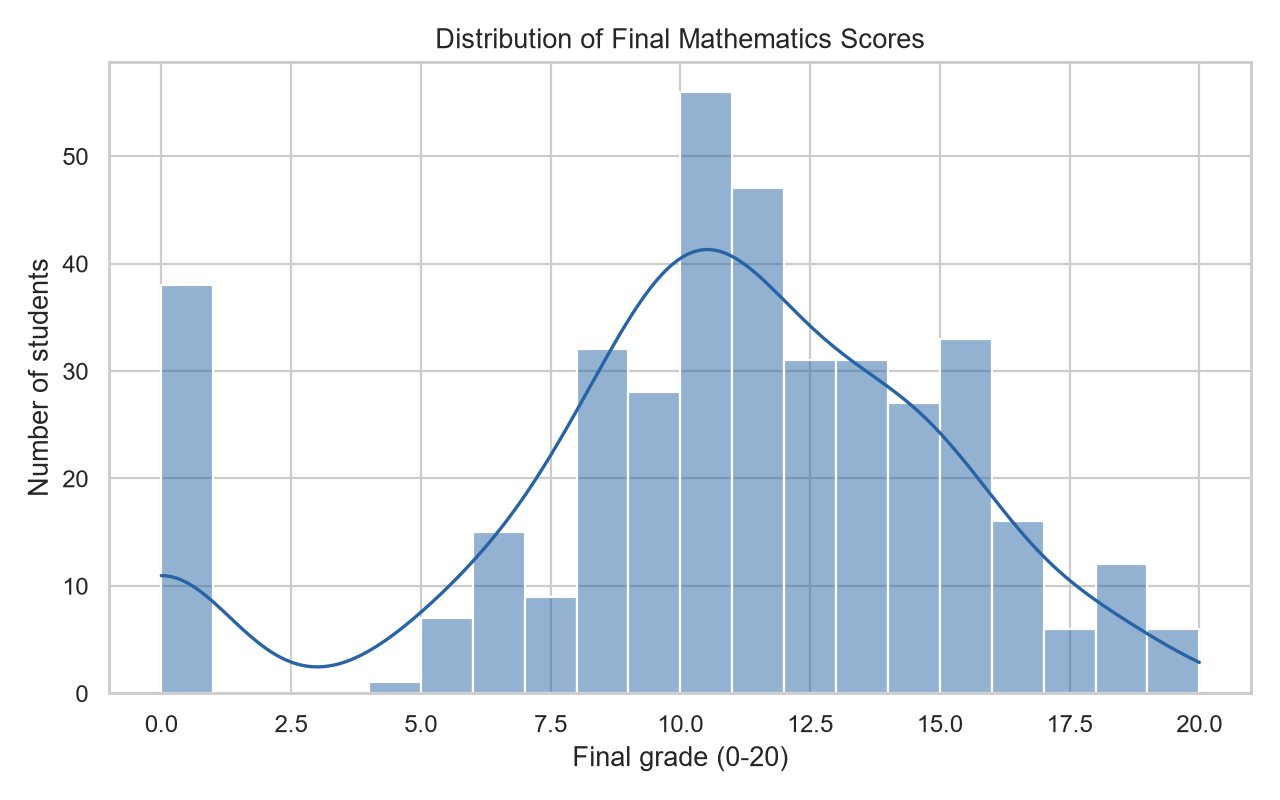

math_score_boxplot.png


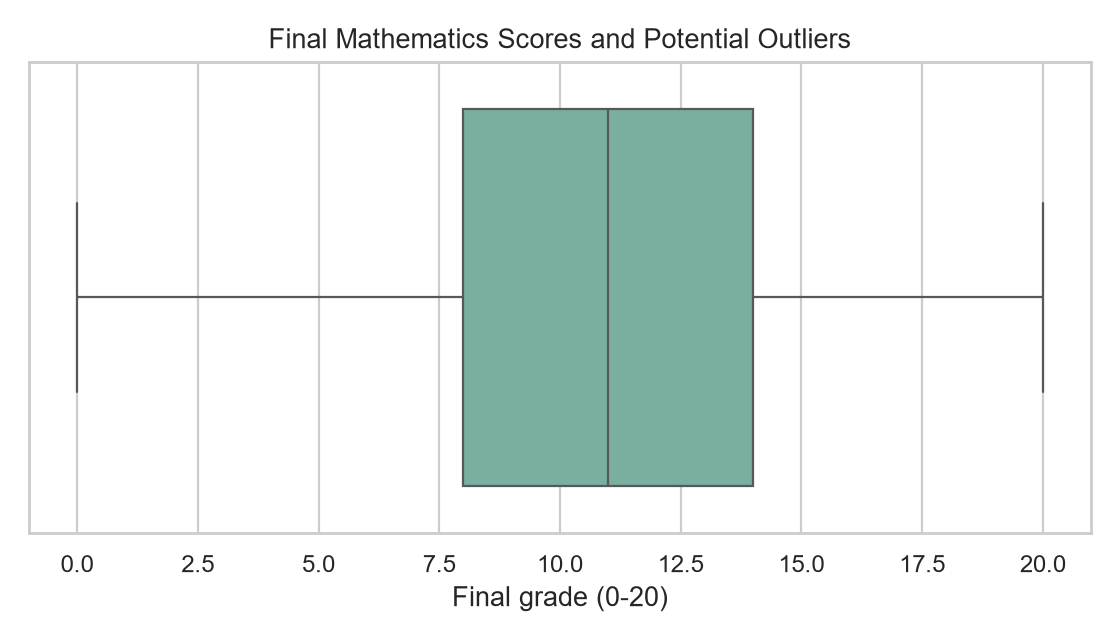

math_scatter_plot.png


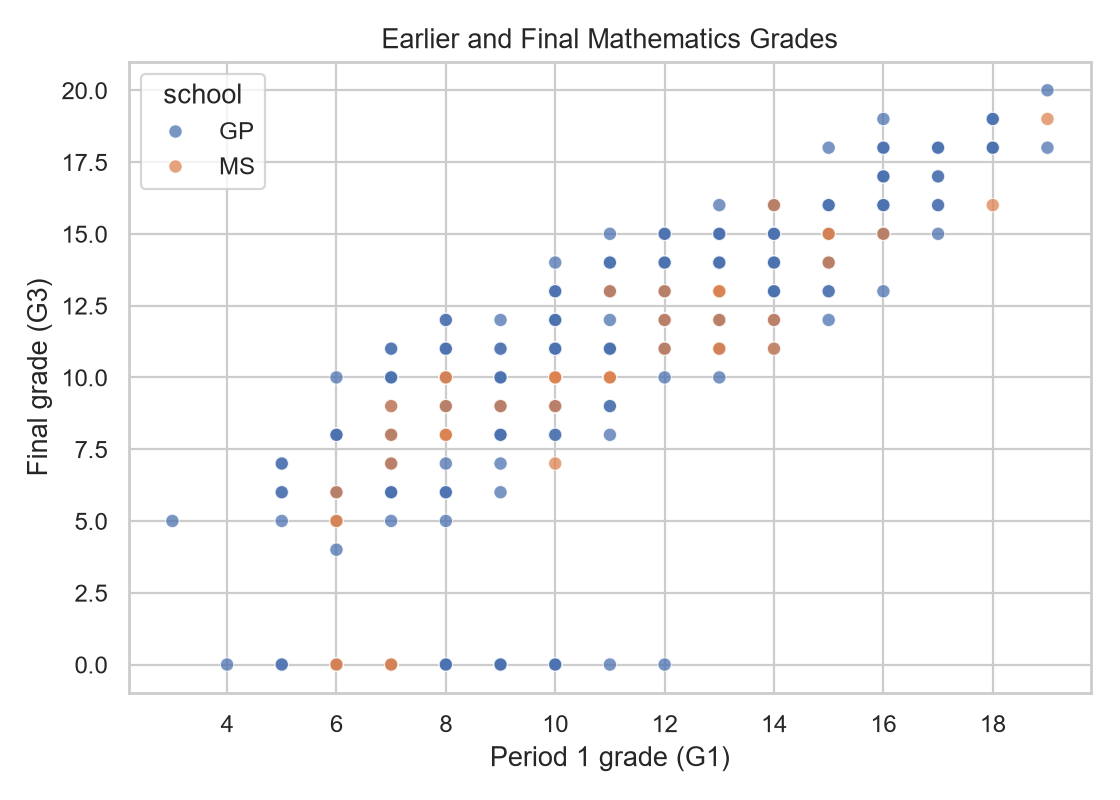

correlation_heatmap.png


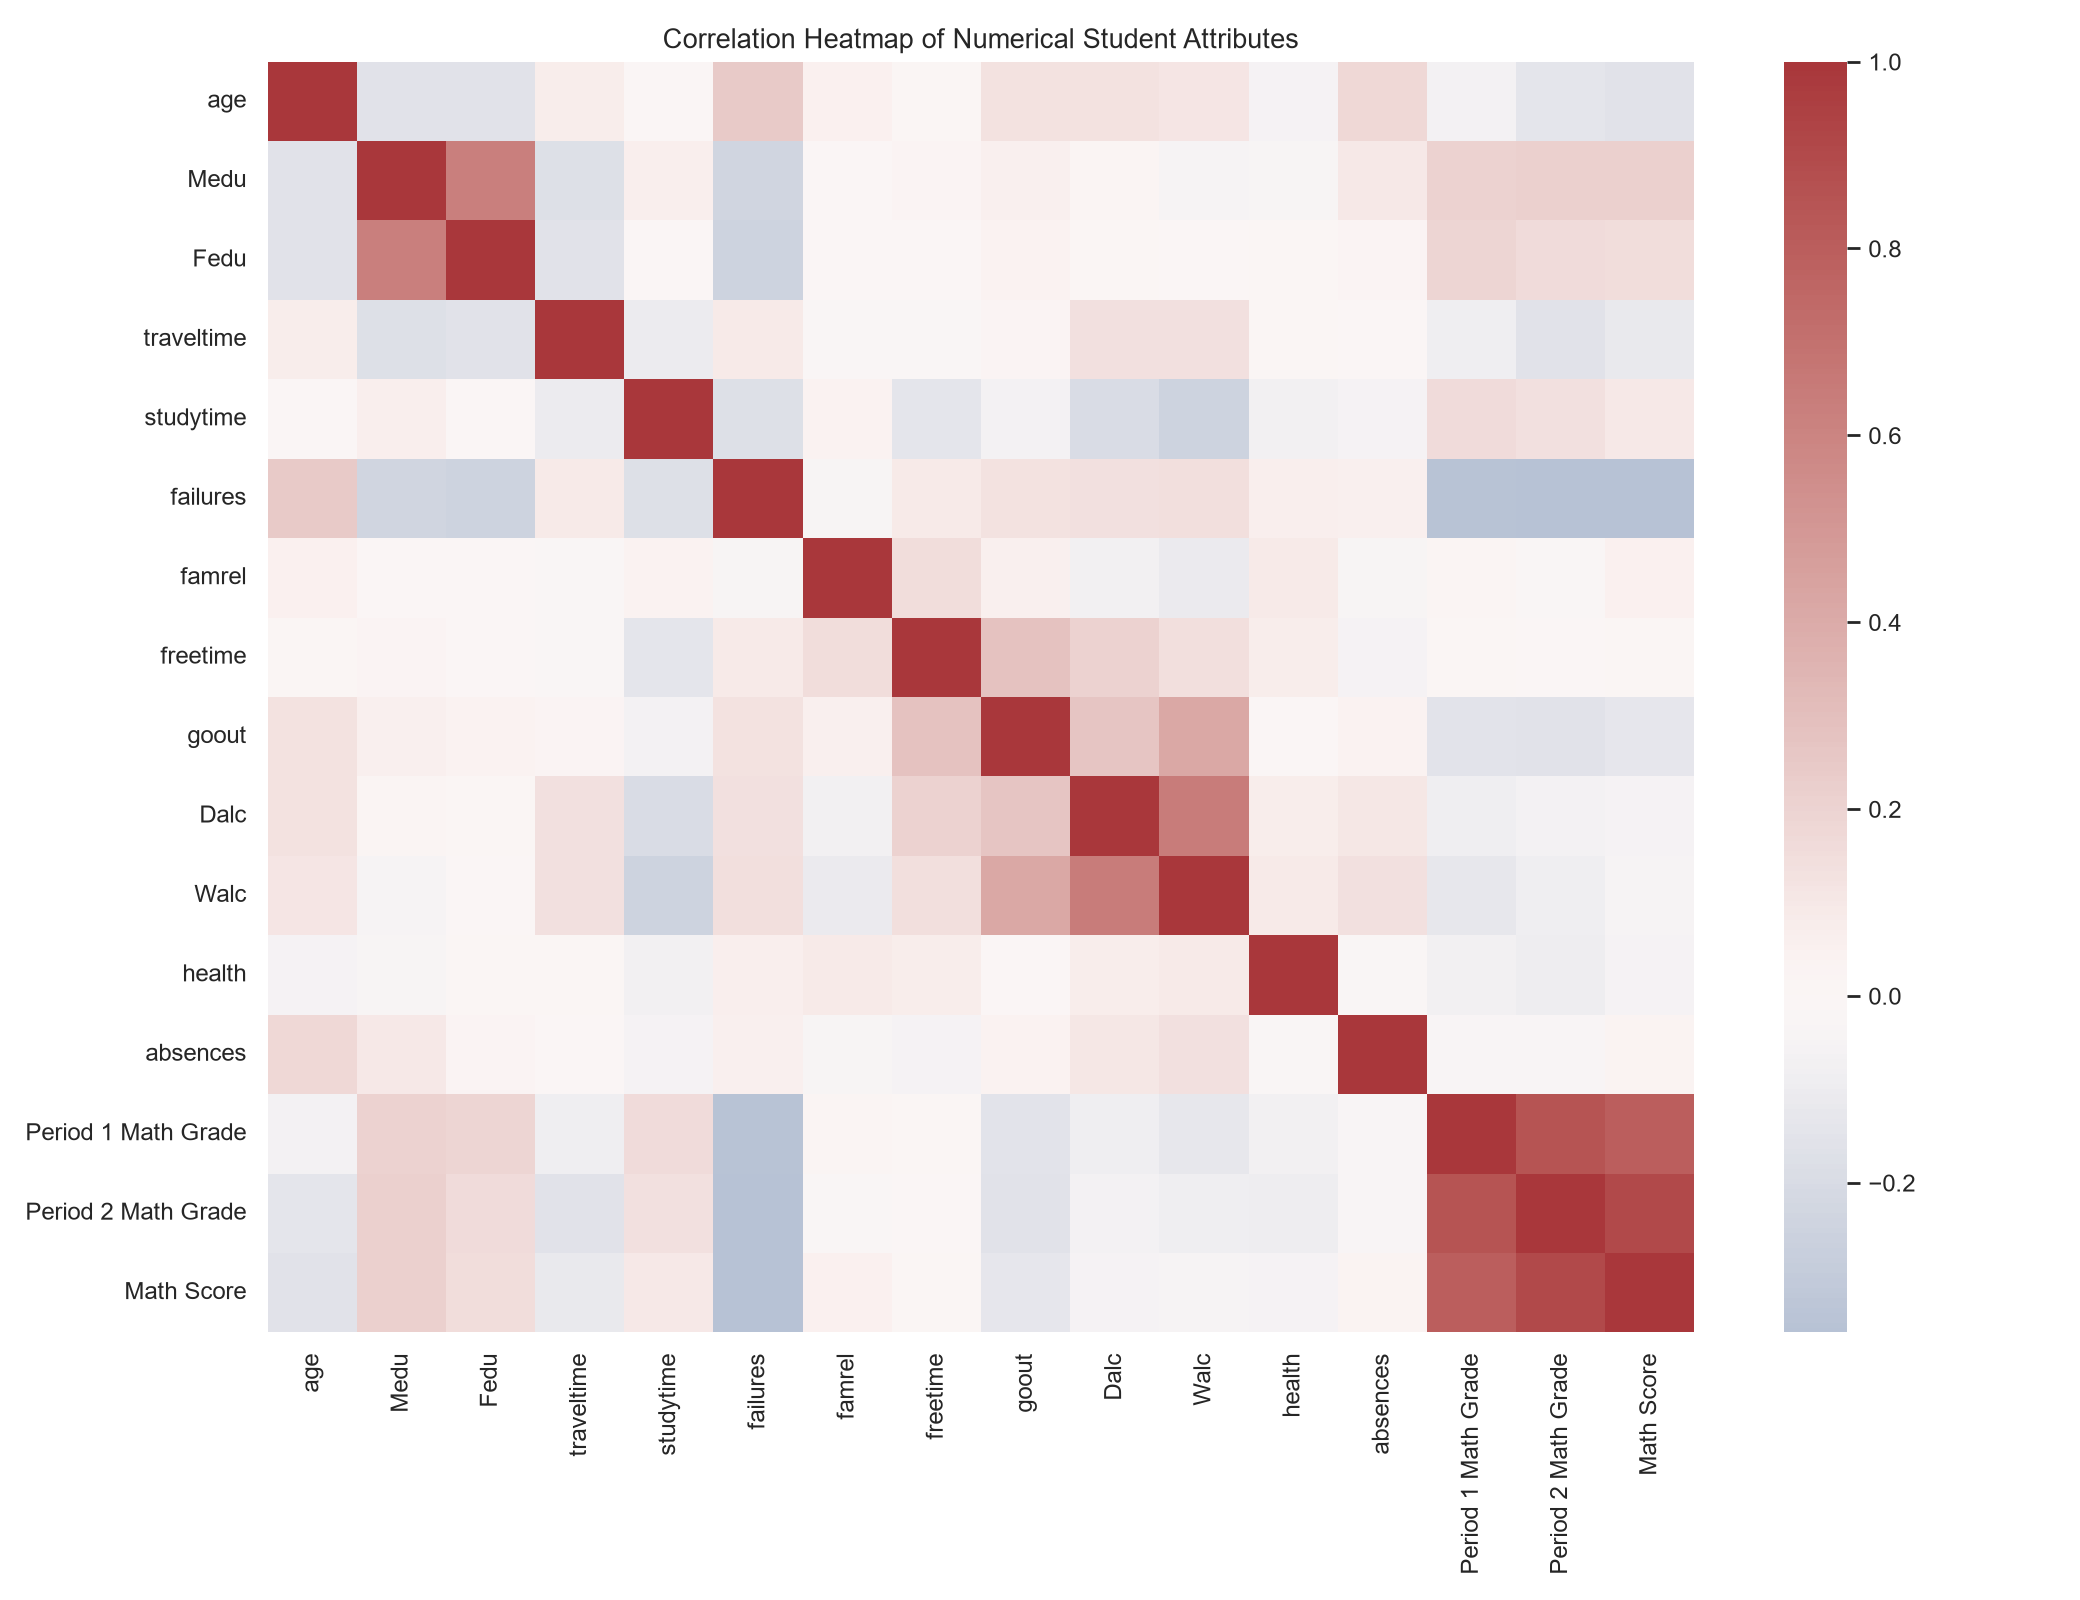

average_score_by_school.png


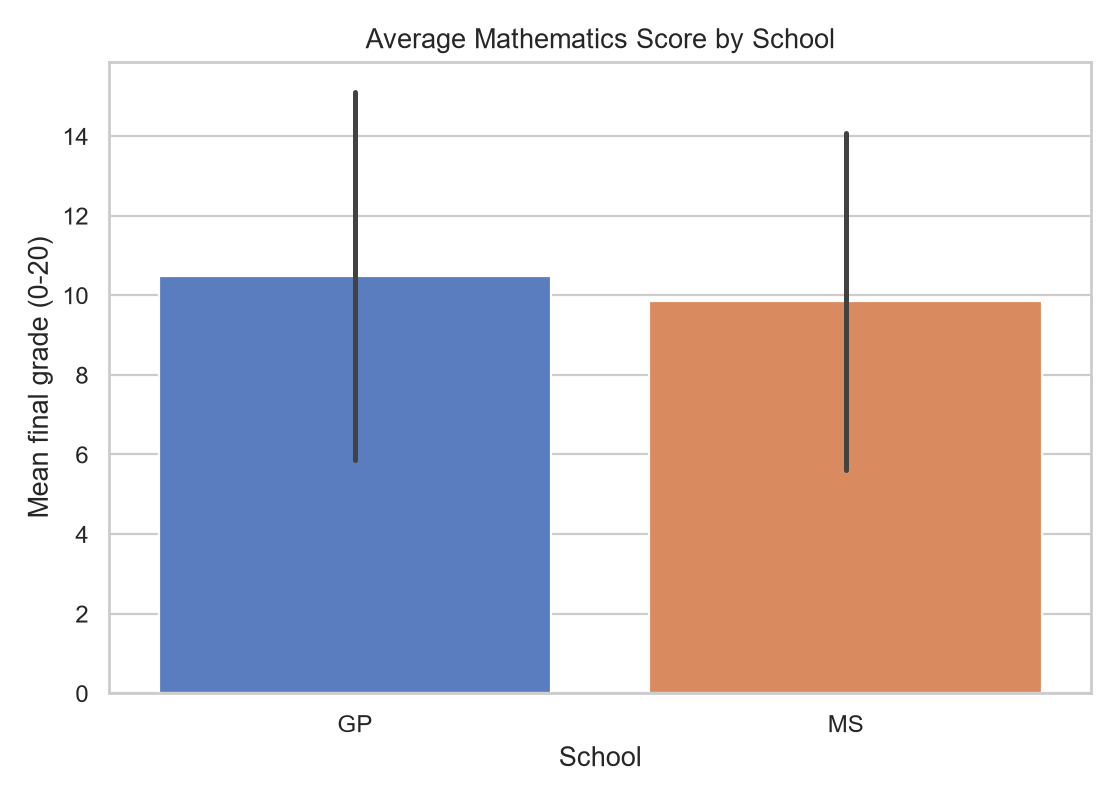

In [4]:
for filename in ['math_score_histogram.png','math_score_boxplot.png','math_scatter_plot.png','correlation_heatmap.png','average_score_by_school.png']:
    print(filename)
    display(Image(filename=str(ROOT / 'images' / filename)))

## Evidence-based observations and limitations
The source contains **395 rows, no missing cells, and no exact duplicate rows**. Final grades average **10.42/20** (median **11**, mode **10**), with Q1 **8** and Q3 **14**; the IQR rule flags **0** observations. The Period 1/final and Period 2/final correlations are **0.801** and **0.905**. Mean final grades are **10.49** at GP and **9.85** at MS. These are descriptive relationships in an observational sample from two Portuguese schools; correlation does not establish causation, and group means do not control for confounders.

## Conclusion
This notebook produces a separately cleaned dataset, quality counts, descriptive statistics, and five labeled figures. See `reports/eda_report.md` for the combined results and limitations.